# Build canonical HCD pseudobulks and scGen training data

This notebook builds donor × cell type × cytokine profiles from the full HCD single-cell dataset. The complete canonical object is the source of truth; the training object is only a filtered subset. This notebook does **not** train scGen or create predictions.

The primary matrix is the mean of cell-level log-normalized expression (`mean_log`). Preprocessed inputs use their stored log-normalized `X`. The raw full HCD input is transformed per cell with the same `normalize_total(target_sum=1e4)` + `log1p` steps used by `subset_hcd.py`, then averaged within profiles. Raw count sums and their per-profile 10,000-library-size `log1p` transform are retained as additional layers. No profiles are removed from the canonical object based on cell count.

## 1. Imports and configuration

In [12]:
from pathlib import Path
import os
import json
import re
import warnings

import numpy as np
import pandas as pd
from scipy import sparse
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad
import scanpy as sc
from IPython.display import display

warnings.filterwarnings('ignore')
np.random.seed(0)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 150})
print('Imports ready')

Imports ready


In [13]:
# Automatic detection supports launching from the repository root or notebooks/.
def find_project_root():
    for candidate in (Path.cwd(), Path.cwd().parent):
        candidate = candidate.resolve()
        if (candidate / 'data').is_dir() and (candidate / 'README.md').exists():
            return candidate
    raise FileNotFoundError('Project root not detected. Set PROJECT_DIR manually below.')

try:
    PROJECT_DIR = find_project_root()
except FileNotFoundError:
    PROJECT_DIR = Path('/path/to/cytoX')  # Manual override: replace if detection fails

DATA_DIR = PROJECT_DIR / 'data'
FULL_DATA_DIR = DATA_DIR / '10M_PBMC_12donor_90cytokines'  # Change if the source is stored elsewhere
PSEUDOBULK_DIR = DATA_DIR / 'pseudobulk'
RESULTS_DIR = DATA_DIR / 'results' / 'pseudobulk'
FULL_DATA_PATH = None  # Set to a discovered H5AD path; never auto-pick among multiple candidates

PRIMARY_AGGREGATION = 'mean_log'
BACKUP_AGGREGATION = 'sum_counts'
MIN_CELLS = 10
TARGET_SUM = 10_000
HOLDOUT_CELL_TYPES = ['NK', 'CD14 Mono']
CONTROL_LABEL = 'PBS'
RANDOM_SEED = 0
ELIGIBILITY_THRESHOLDS = [5, 10, 20]

# Set explicitly if automatic exact-name detection is ambiguous or not applicable.
DONOR_KEY = None
CELL_TYPE_KEY = None
CYTOKINE_KEY = None
COUNTS_LAYER = 'counts'
ALLOW_LOG_NORMALIZE_RAW_X = True  # Reproduce subset_hcd.py preprocessing for raw full data

PSEUDOBULK_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print('Project root:', PROJECT_DIR)
print('Expected full-data directory:', FULL_DATA_DIR)
print('Output directory:', PSEUDOBULK_DIR)

Project root: /Users/svneni/f26/idl/cyto-project/cytoX
Expected full-data directory: /Users/svneni/f26/idl/cyto-project/cytoX/data/10M_PBMC_12donor_90cytokines
Output directory: /Users/svneni/f26/idl/cyto-project/cytoX/data/pseudobulk


## 2. Input dataset loading and validation

First list candidate files. If more than one candidate is present, explicitly set `FULL_DATA_PATH` in the configuration cell; the notebook will not guess which file is the intended full dataset. Review the observation metadata before setting any of the key-column overrides.

The repository's `subset_hcd.py` copies raw counts to a `counts` layer, then runs Scanpy `normalize_total(target_sum=1e4)` and `log1p`. That processed `hcd_subset.h5ad` contains those transformed values, but it is only a 54k-cell, 7k-gene subset. The 9.7M-cell full HCD file is still raw counts in `X` (and has no usable named counts layer). To keep the full gene/cell universe, this notebook can reproduce that same per-cell transform on the fly during aggregation without modifying the source. It uses precomputed log `X` directly when the selected input already has valid log metadata and a raw-count layer.

In [14]:
def discover_h5ad_files():
    search_root = FULL_DATA_DIR if FULL_DATA_DIR.is_dir() else DATA_DIR
    excluded_parts = {'pseudobulk', 'pseudobulks', 'pseudobulk_runs', 'pseudobulk_runs_full', 'results'}
    files = []
    for path in search_root.rglob('*.h5ad'):
        relative_parts = path.relative_to(search_root).parts
        if any(part.lower() in excluded_parts for part in relative_parts):
            continue
        files.append(path.resolve())
    return sorted(set(files))

candidate_files = discover_h5ad_files()
display(pd.DataFrame([{'candidate': str(p), 'size_gb': round(p.stat().st_size / (1024**3), 3)}
                      for p in candidate_files]))
if FULL_DATA_PATH is None:
    if len(candidate_files) == 1:
        FULL_DATA_PATH = candidate_files[0]
        print('Using the only discovered candidate:', FULL_DATA_PATH)
    else:
        raise ValueError(
            f'Found {len(candidate_files)} candidate H5AD files. Set FULL_DATA_PATH explicitly '
            'in the configuration cell after reviewing the list above.'
        )
else:
    FULL_DATA_PATH = Path(FULL_DATA_PATH).expanduser().resolve()
    if not FULL_DATA_PATH.is_file():
        raise FileNotFoundError(f'FULL_DATA_PATH does not exist: {FULL_DATA_PATH}')
print('Selected input:', FULL_DATA_PATH)

,candidate,size_gb
0,/Users/svneni/f26/idl/cyto-project/cytoX/data/...,41.321


Using the only discovered candidate: /Users/svneni/f26/idl/cyto-project/cytoX/data/10M_PBMC_12donor_90cytokines/10M_PBMC_cytokines.h5ad
Selected input: /Users/svneni/f26/idl/cyto-project/cytoX/data/10M_PBMC_12donor_90cytokines/10M_PBMC_cytokines.h5ad


In [15]:
# Backed mode leaves the large expression matrix on disk; obs/var metadata remain inspectable.
adata = ad.read_h5ad(FULL_DATA_PATH, backed='r')
print(adata)
print(f'Cells: {adata.n_obs:,} | genes: {adata.n_vars:,}')
print('obs columns:', list(adata.obs.columns))
print('Representative obs rows:')
display(adata.obs.head())
print('var columns:', list(adata.var.columns))
print('Representative var rows:')
display(adata.var.head())
print('Layers:', list(adata.layers.keys()))
print('uns keys:', list(adata.uns.keys()))
print('X storage type:', type(adata.X).__name__)
print('X sparse:', sparse.issparse(adata.X) or hasattr(adata.X, 'format'))

# Exact conventional names are suggested only when present; no fuzzy replacement is made.
def suggest_exact_column(columns, candidates):
    matches = [name for name in candidates if name in columns]
    return matches[0] if len(matches) == 1 else None

if DONOR_KEY is None:
    DONOR_KEY = suggest_exact_column(adata.obs.columns, ['donor'])
if CELL_TYPE_KEY is None:
    CELL_TYPE_KEY = suggest_exact_column(adata.obs.columns, ['cell_type', 'celltype'])
if CYTOKINE_KEY is None:
    CYTOKINE_KEY = suggest_exact_column(adata.obs.columns, ['cytokine'])

print('Selected metadata keys:', {'donor': DONOR_KEY, 'cell_type': CELL_TYPE_KEY, 'cytokine': CYTOKINE_KEY})
for key in [DONOR_KEY, CELL_TYPE_KEY, CYTOKINE_KEY]:
    if key is not None:
        print(f'\n{key}: {adata.obs[key].nunique(dropna=True)} unique values; missing={adata.obs[key].isna().sum()}')
        display(adata.obs[key].value_counts(dropna=False).rename('cells').to_frame())

AnnData object with n_obs × n_vars = 9697974 × 40352 backed at '/Users/svneni/f26/idl/cyto-project/cytoX/data/10M_PBMC_12donor_90cytokines/10M_PBMC_cytokines.h5ad'
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type'
    var: 'n_cells'
    layers: None (.X)
Cells: 9,697,974 | genes: 40,352
obs columns: ['sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type']
Representative obs rows:


,sample,species,gene_count,tscp_count,mread_count,bc1_wind,bc2_wind,bc3_wind,bc1_well,bc2_well,bc3_well,log1p_n_genes_by_counts,log1p_total_counts,total_counts_MT,pct_counts_MT,log1p_total_counts_MT,donor,cytokine,treatment,cell_type
89_103_005__s1,Donor10_4-1BBL,hg38,2236,4700,8656,89,103,5,H5,p2.A7,A5,7.712891,8.455530,56.0,1.191490,4.043051,Donor10,4-1BBL,cytokine,CD8 Naive
89_103_083__s1,Donor10_4-1BBL,hg38,2222,4337,8235,89,103,83,H5,p2.A7,G11,7.706613,8.375169,71.0,1.637076,4.276666,Donor10,4-1BBL,cytokine,B Naive
89_103_085__s1,Donor10_4-1BBL,hg38,1690,3079,5870,89,103,85,H5,p2.A7,H1,7.433075,8.032685,197.0,6.398181,5.288267,Donor10,4-1BBL,cytokine,B Intermediate/Memory
89_104_009__s1,Donor10_4-1BBL,hg38,1746,3015,5663,89,104,9,H5,p2.A8,A9,7.465655,8.011686,84.0,2.786070,4.442651,Donor10,4-1BBL,cytokine,CD14 Mono
89_104_025__s1,Donor10_4-1BBL,hg38,3182,6986,13153,89,104,25,H5,p2.A8,C1,8.065579,8.851807,165.0,2.361867,5.111988,Donor10,4-1BBL,cytokine,CD14 Mono


var columns: ['n_cells']
Representative var rows:


,n_cells
TSPAN6,15700
TNMD,585
DPM1,1984849
SCYL3,2042340
C1orf112,1378182


Layers: [None]
uns keys: []
X storage type: _CSRDataset
X sparse: True
Selected metadata keys: {'donor': 'donor', 'cell_type': 'cell_type', 'cytokine': 'cytokine'}

donor: 12 unique values; missing=0


,cells
donor,
Donor1,1267690
Donor5,1066725
Donor12,1054708
Donor6,974030
Donor2,931569
Donor3,695158
Donor7,652386
Donor8,650974
Donor9,632341



cell_type: 18 unique values; missing=0


,cells
cell_type,
CD4 Memory,2376445
CD4 Naive,1725983
CD14 Mono,1582568
CD8 Memory,757585
B Naive,625239
CD8 Naive,619816
NK,512565
B Intermediate/Memory,326661
MAIT,322923



cytokine: 91 unique values; missing=0


,cells
cytokine,
PBS,629701
CT-1,136899
IL-36-alpha,135264
IL-9,130692
TSLP,129206
...,...
IL-11,82049
IL-17B,81210
BAFF,77408


In [16]:
def sparse_aware_sample(matrix, n_rows=200, n_cols=1000, seed=0):
    rng = np.random.default_rng(seed)
    n_obs, n_vars = matrix.shape
    rows = np.sort(rng.choice(n_obs, min(n_rows, n_obs), replace=False))
    cols = rng.choice(n_vars, min(n_cols, n_vars), replace=False)
    sample = matrix[rows, :][:, cols]
    return sample.toarray() if sparse.issparse(sample) else np.asarray(sample)

def sample_matrix_summary(matrix, label, seed=0):
    values = sparse_aware_sample(matrix, n_rows=150, n_cols=800, seed=seed).astype(np.float64, copy=False).ravel()
    return {
        'matrix': label, 'dtype': str(getattr(matrix, 'dtype', 'unknown')),
        'sparse': sparse.issparse(matrix) or hasattr(matrix, 'format'),
        'sample_min': float(np.min(values)), 'sample_max': float(np.max(values)),
        'sample_mean': float(np.mean(values)), 'sample_median': float(np.median(values)),
        'negative_values': bool(np.any(values < 0)),
        'nan_values': bool(np.isnan(values).any()), 'infinite_values': bool(np.isinf(values).any()),
        'integer_like_fraction': float(np.mean(np.isclose(values, np.round(values)))),
    }

matrix_summaries = [sample_matrix_summary(adata.X, 'X', RANDOM_SEED)]
if COUNTS_LAYER in adata.layers:
    matrix_summaries.append(sample_matrix_summary(adata.layers[COUNTS_LAYER], f'layer:{COUNTS_LAYER}', RANDOM_SEED + 1))
display(pd.DataFrame(matrix_summaries))
print('log1p metadata:', adata.uns.get('log1p', '<missing>'))

,matrix,dtype,sparse,sample_min,sample_max,sample_mean,sample_median,negative_values,nan_values,infinite_values,integer_like_fraction
0,X,float32,True,0.0,63.0,0.074342,0.0,False,False,False,1.0


log1p metadata: <missing>


In [17]:
# Check label cardinalities and identifiers before any matrix aggregation.
if any(key is None for key in [DONOR_KEY, CELL_TYPE_KEY, CYTOKINE_KEY]):
    raise ValueError(
        'Set DONOR_KEY, CELL_TYPE_KEY, and CYTOKINE_KEY in the configuration cell. '
        f'Available obs columns: {list(adata.obs.columns)}'
    )
required_keys = [DONOR_KEY, CELL_TYPE_KEY, CYTOKINE_KEY]
missing_columns = sorted(set(required_keys) - set(adata.obs.columns))
if missing_columns:
    raise KeyError(f'Required metadata columns not found: {missing_columns}')

label_report = pd.DataFrame([
    {'role': role, 'column': key, 'n_unique': int(adata.obs[key].nunique(dropna=True)),
     'n_missing': int(adata.obs[key].isna().sum()),
     'values': ', '.join(map(str, adata.obs[key].dropna().unique()[:30]))}
    for role, key in zip(['donor', 'cell_type', 'cytokine'], required_keys)
])
display(label_report)
print('Unique genes:', adata.var_names.is_unique)
print('Control label present:', CONTROL_LABEL in set(adata.obs[CYTOKINE_KEY].dropna().astype(str)))

,role,column,n_unique,n_missing,values
0,donor,donor,12,0,"Donor10, Donor11, Donor12, Donor1, Donor2, Don..."
1,cell_type,cell_type,18,0,"CD8 Naive, B Naive, B Intermediate/Memory, CD1..."
2,cytokine,cytokine,91,0,"4-1BBL, ADSF, APRIL, BAFF, Megalin, C5a, CD27L..."


Unique genes: True
Control label present: True


In [18]:
# Accept either documented preprocessed input, or raw integer-like X that can be transformed
# using the exact normalize_total + log1p procedure used by subset_hcd.py.
x_summary = matrix_summaries[0]
log_metadata = adata.uns.get('log1p')
log_metadata_present = isinstance(log_metadata, dict) and len(log_metadata) > 0
x_looks_transformed = (
    not x_summary['negative_values'] and
    x_summary['integer_like_fraction'] < 0.99 and
    x_summary['sample_max'] <= 100
)
counts_available = COUNTS_LAYER in adata.layers
counts_summary = next((item for item in matrix_summaries if item['matrix'] == f'layer:{COUNTS_LAYER}'), None)
counts_valid = counts_summary is not None and (
    not counts_summary['negative_values'] and counts_summary['integer_like_fraction'] >= 0.99
)
x_is_raw_counts = not x_summary['negative_values'] and x_summary['integer_like_fraction'] >= 0.99
if x_looks_transformed and log_metadata_present and counts_valid:
    EXPRESSION_MODE = 'existing_log_normalized_X'
    RAW_COUNTS_MATRIX = adata.layers[COUNTS_LAYER]
    RAW_COUNTS_SOURCE = f"layers[{COUNTS_LAYER!r}]"
elif x_is_raw_counts and ALLOW_LOG_NORMALIZE_RAW_X:
    EXPRESSION_MODE = 'derive_log_normalized_values_from_raw_X'
    if counts_valid:
        RAW_COUNTS_MATRIX = adata.layers[COUNTS_LAYER]
        RAW_COUNTS_SOURCE = f"layers[{COUNTS_LAYER!r}]"
    else:
        RAW_COUNTS_MATRIX = adata.X
        RAW_COUNTS_SOURCE = 'X (verified integer-like raw counts)'
    print('No precomputed log-normalized X found; deriving cell-level log-normalized values using',
          f'normalize_total(target_sum={TARGET_SUM}) then log1p, matching subset_hcd.py.')
else:
    EXPRESSION_MODE = None
    RAW_COUNTS_MATRIX = None
    RAW_COUNTS_SOURCE = None
missing_label_counts = {key: int(adata.obs[key].isna().sum()) for key in required_keys}
validation_issues = []
if not adata.var_names.is_unique:
    validation_issues.append('Gene identifiers are not unique.')
if any(missing_label_counts.values()):
    validation_issues.append(f'Missing donor/cell-type/cytokine labels: {missing_label_counts}')
if EXPRESSION_MODE is None:
    validation_issues.append(
        'Could not verify a usable expression source. Expected either log-normalized X with '
        f"uns['log1p'] and a valid '{COUNTS_LAYER}' layer, or nonnegative integer-like raw X "
        'with ALLOW_LOG_NORMALIZE_RAW_X enabled.'
    )
if CONTROL_LABEL not in set(adata.obs[CYTOKINE_KEY].dropna().astype(str)):
    validation_issues.append(f'Control condition {CONTROL_LABEL!r} is absent from {CYTOKINE_KEY!r}.')

if validation_issues:
    print('Input validation failed:')
    for issue in validation_issues:
        print('-', issue)
    raise ValueError(
        'Cannot safely construct the requested canonical dataset. Select a compatible '
        'preprocessed H5AD or verify that raw X contains integer-like counts and enable '
        'the documented per-cell normalization/log1p step.'
    )
print('Expression mode:', EXPRESSION_MODE)
print('Raw count source:', RAW_COUNTS_SOURCE)
print('Input representations and grouping metadata passed validation.')

No precomputed log-normalized X found; deriving cell-level log-normalized values using normalize_total(target_sum=10000) then log1p, matching subset_hcd.py.
Expression mode: derive_log_normalized_values_from_raw_X
Raw count source: X (verified integer-like raw counts)
Input representations and grouping metadata passed validation.


### Validation interpretation

For preprocessed files, the notebook uses `X` only when its `uns['log1p']` metadata and sampled values support that interpretation, and uses the configured count layer for raw sums. For raw full HCD, integer-like nonnegative `X` is explicitly treated as counts and transformed cell-by-cell using the documented `subset_hcd.py` recipe. This does not mutate the source or normalize aggregated counts to create `mean_log`; it reproduces the per-cell normalization/log transform before averaging.

## 3. Pseudobulk aggregation

All observed donor × cell type × cytokine groups are retained, including groups with fewer than `MIN_CELLS`. For preprocessed inputs, the code averages stored log-normalized `X`. For raw full HCD, it computes each cell's normalized/log-transformed expression within the group and then averages those values. In both cases, raw counts are summed separately; each count sum is independently normalized to `TARGET_SUM` per profile and transformed with `log1p`.

In [19]:
def validate_aggregation_inputs(adata, donor_key, cell_type_key, cytokine_key, raw_counts_matrix):
    keys = [donor_key, cell_type_key, cytokine_key]
    if raw_counts_matrix is None or (not sparse.issparse(raw_counts_matrix) and not hasattr(raw_counts_matrix, 'format')):
        raise TypeError('Expected a verified sparse raw-count matrix for memory-safe aggregation.')
    if EXPRESSION_MODE == 'existing_log_normalized_X' and not (sparse.issparse(adata.X) or hasattr(adata.X, 'format')):
        raise TypeError('Expected sparse log-normalized X for memory-safe aggregation.')
    if EXPRESSION_MODE not in {'existing_log_normalized_X', 'derive_log_normalized_values_from_raw_X'}:
        raise ValueError(f'Unsupported expression mode: {EXPRESSION_MODE!r}')
    if adata.obs[keys].isna().any().any():
        raise ValueError('Grouping columns contain missing values; resolve before aggregation.')
    return keys

def profile_identifier(values):
    def slug(value):
        return re.sub(r'[^A-Za-z0-9.-]+', '-', str(value)).strip('-')[:48] or 'NA'
    return 'pb_' + '__'.join(slug(value) for value in values)

def aggregate_canonical(adata, donor_key, cell_type_key, cytokine_key, raw_counts_matrix, target_sum):
    keys = validate_aggregation_inputs(adata, donor_key, cell_type_key, cytokine_key, raw_counts_matrix)
    obs = adata.obs
    grouped = obs.groupby(keys, observed=True, sort=True).indices
    mean_rows, raw_count_rows, metadata_rows = [], [], []

    for group_values, row_indices in grouped.items():
        if not isinstance(group_values, tuple):
            group_values = (group_values,)
        row_indices = np.sort(np.asarray(row_indices, dtype=np.int64))
        n_cells = len(row_indices)
        if n_cells == 0:
            continue

        count_group = raw_counts_matrix[row_indices, :]
        if not sparse.issparse(count_group):
            count_group = sparse.csr_matrix(count_group)

        if EXPRESSION_MODE == 'existing_log_normalized_X':
            x_group = adata.X[row_indices, :]
            if not sparse.issparse(x_group):
                x_group = sparse.csr_matrix(x_group)
        else:
            cell_totals = np.asarray(count_group.sum(axis=1)).ravel().astype(np.float64)
            if np.any(cell_totals <= 0):
                raise ValueError(f'Zero-total raw-count cells encountered in group {group_values}.')
            cell_scale = (float(target_sum) / cell_totals).astype(np.float32)
            x_group = sparse.diags(cell_scale, format='csr').dot(count_group.astype(np.float32)).tocsr()
            x_group.data = np.log1p(x_group.data)
        mean_row = sparse.csr_matrix(x_group.mean(axis=0), dtype=np.float32)
        count_row = sparse.csr_matrix(count_group.astype(np.int64).sum(axis=0), dtype=np.int64)
        mean_rows.append(mean_row)
        raw_count_rows.append(count_row)
        donor, cell_type, cytokine = map(str, group_values)
        metadata_rows.append({
            'donor': donor, 'cell_type': cell_type, 'cytokine': cytokine,
            'condition': 'control' if cytokine == str(CONTROL_LABEL) else 'stimulated',
            'n_cells': int(n_cells),
        })

    if not metadata_rows:
        raise ValueError('No nonempty groups found for pseudobulk aggregation.')
    metadata = pd.DataFrame(metadata_rows)
    metadata.index = [
        f'pb_{i:07d}_' + profile_identifier(row)[3:]
        for i, row in enumerate(metadata[['donor', 'cell_type', 'cytokine']].itertuples(index=False, name=None))
    ]
    if not metadata.index.is_unique:
        raise ValueError('Generated profile identifiers are not unique; adjust profile_identifier().')

    mean_log = sparse.vstack(mean_rows, format='csr', dtype=np.float32)
    sum_counts_raw = sparse.vstack(raw_count_rows, format='csr', dtype=np.int64)
    raw_library_sizes = np.asarray(sum_counts_raw.sum(axis=1)).ravel().astype(np.float64)
    if np.any(raw_library_sizes <= 0):
        bad = np.flatnonzero(raw_library_sizes <= 0).tolist()[:20]
        raise ValueError(f'Zero-total raw-count profiles found at row indices {bad}.')

    scale = (float(target_sum) / raw_library_sizes).astype(np.float32)
    sum_counts_log1p = sparse.diags(scale, format='csr').dot(sum_counts_raw).tocsr()
    sum_counts_log1p.data = np.log1p(sum_counts_log1p.data)
    sum_counts_log1p = sum_counts_log1p.astype(np.float32)

    result = ad.AnnData(X=mean_log, obs=metadata, var=adata.var.copy())
    result.layers['sum_counts_raw'] = sum_counts_raw
    result.layers['sum_counts_log1p'] = sum_counts_log1p
    result.obs['raw_library_size'] = raw_library_sizes
    result.uns['pseudobulk'] = {
        'grouping': 'donor x cell_type x cytokine',
        'primary_aggregation': 'mean_log = mean(cell-level log-normalized expression)',
        'backup_aggregation': 'sum raw-count layer, normalize each profile to target_sum, then log1p',
        'expression_mode': str(EXPRESSION_MODE), 'raw_counts_source': str(RAW_COUNTS_SOURCE),
        'counts_layer': str(COUNTS_LAYER), 'target_sum': float(target_sum),
        'control_label': str(CONTROL_LABEL), 'min_cells_for_training': int(MIN_CELLS),
        'profile_count': int(result.n_obs), 'gene_count': int(result.n_vars),
    }
    return result

canonical = aggregate_canonical(
    adata, DONOR_KEY, CELL_TYPE_KEY, CYTOKINE_KEY, RAW_COUNTS_MATRIX, TARGET_SUM
)
print(canonical)
print('Canonical profiles:', canonical.n_obs)
display(canonical.obs.head())

AnnData object with n_obs × n_vars = 19459 × 40352
    obs: 'donor', 'cell_type', 'cytokine', 'condition', 'n_cells', 'raw_library_size'
    var: 'n_cells'
    uns: 'pseudobulk'
    layers: None (.X), 'sum_counts_raw', 'sum_counts_log1p'
Canonical profiles: 19459


,donor,cell_type,cytokine,condition,n_cells,raw_library_size
pb_0000000_Donor1__B-Intermediate-Memory__4-1BBL,Donor1,B Intermediate/Memory,4-1BBL,stimulated,300,1359900.0
pb_0000001_Donor1__B-Intermediate-Memory__ADSF,Donor1,B Intermediate/Memory,ADSF,stimulated,274,1606829.0
pb_0000002_Donor1__B-Intermediate-Memory__APRIL,Donor1,B Intermediate/Memory,APRIL,stimulated,117,671292.0
pb_0000003_Donor1__B-Intermediate-Memory__BAFF,Donor1,B Intermediate/Memory,BAFF,stimulated,197,1479829.0
pb_0000004_Donor1__B-Intermediate-Memory__C5a,Donor1,B Intermediate/Memory,C5a,stimulated,200,1199180.0


## 4. Canonical dataset quality checks and EDA

,canonical_profiles,donors,cell_types,cytokine_conditions,genes
0,19459,12,18,91,40352


Profiles per cell_type


,profiles
cell_type,
B Intermediate/Memory,1092
B Naive,1092
CD14 Mono,1092
CD16 Mono,1090
CD4 Memory,1092
CD4 Naive,1092
CD8 Memory,1092
CD8 Naive,1092
HSPC,1092


Profiles per cytokine


,profiles
cytokine,
4-1BBL,213
ADSF,213
APRIL,215
BAFF,210
C5a,212
...,...
TPO,214
TRAIL,215
TSLP,214


Profiles per donor


,profiles
donor,
Donor1,1636
Donor10,1633
Donor11,1608
Donor12,1635
Donor2,1630
Donor3,1627
Donor4,1635
Donor5,1597
Donor6,1614


,n_cells
count,19459.000000
mean,498.379876
std,908.511450
min,1.000000
10%,6.000000
25%,34.000000
50%,201.000000
75%,542.000000
90%,1351.000000
max,26545.000000


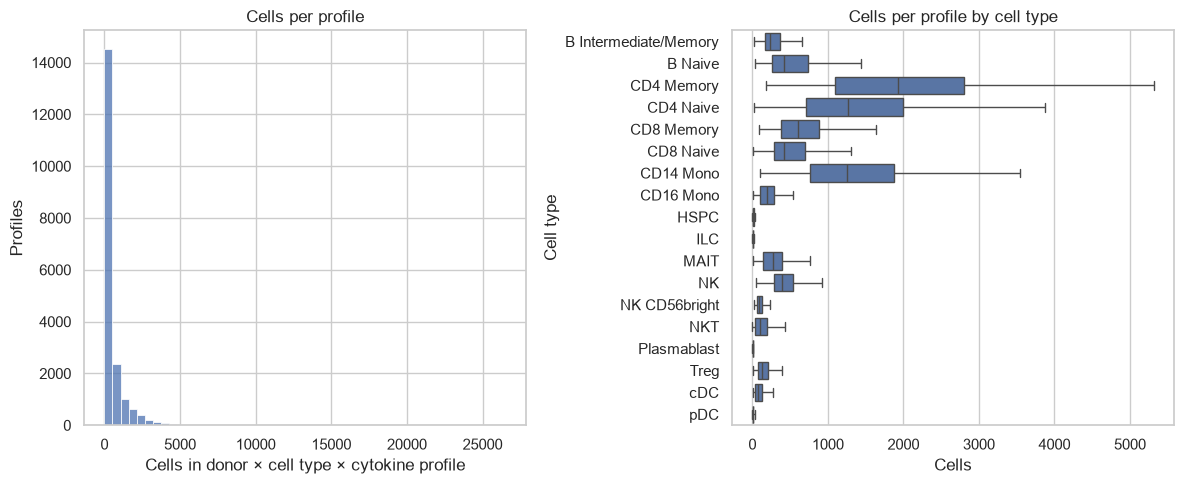

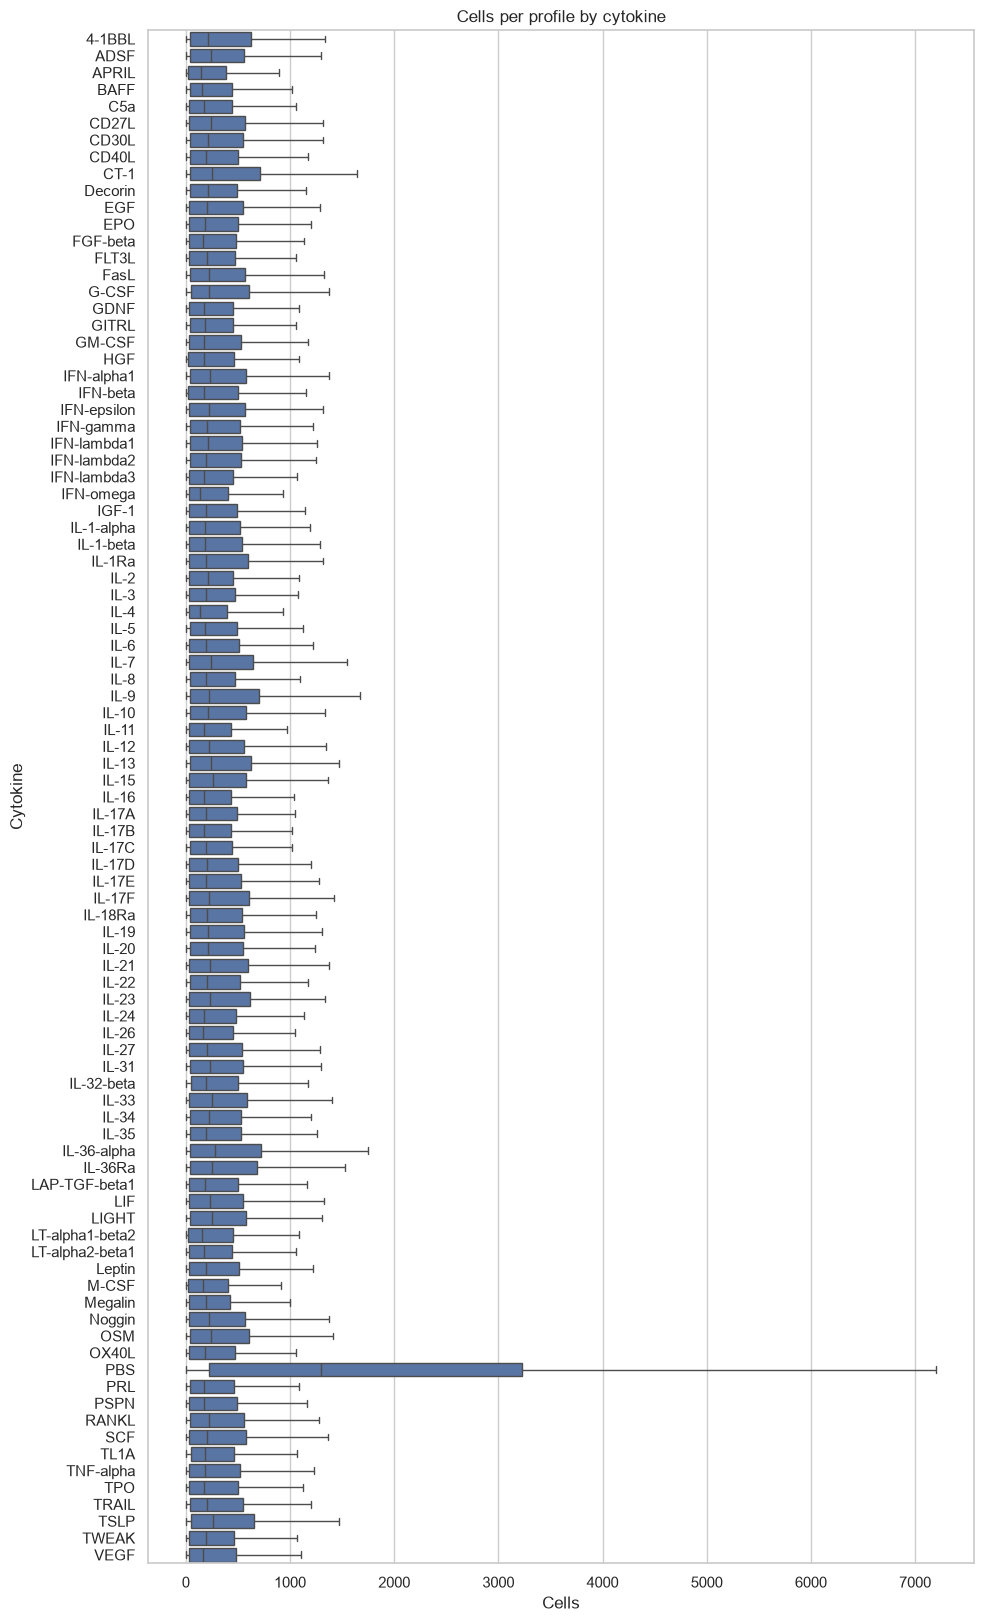

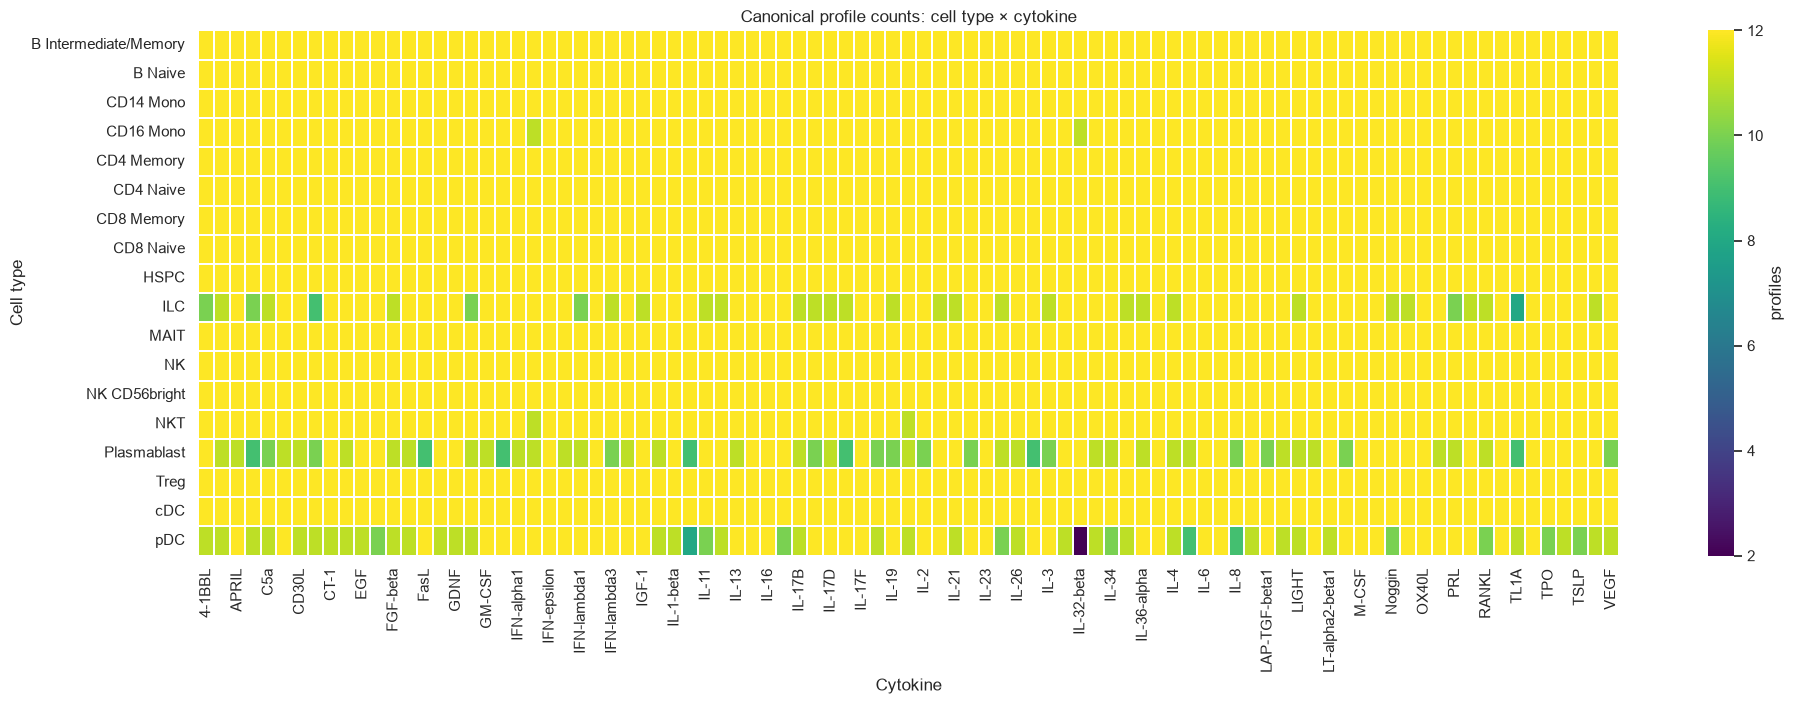

Low-cell canonical profiles are retained:
n_cells < 5: 1,429
n_cells < 10: 2,747
n_cells < 20: 4,039


In [20]:
canonical_obs = canonical.obs
profile_counts = {
    'canonical_profiles': int(canonical.n_obs),
    'donors': int(canonical_obs['donor'].nunique()),
    'cell_types': int(canonical_obs['cell_type'].nunique()),
    'cytokine_conditions': int(canonical_obs['cytokine'].nunique()),
    'genes': int(canonical.n_vars),
}
display(pd.DataFrame([profile_counts]))
for column in ['cell_type', 'cytokine', 'donor']:
    print(f'Profiles per {column}')
    display(canonical_obs[column].value_counts().sort_index().rename('profiles').to_frame())

cell_stats = canonical_obs['n_cells'].describe(percentiles=[.1, .25, .5, .75, .9]).to_frame('n_cells')
display(cell_stats)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(canonical_obs['n_cells'], bins=50, ax=axes[0])
axes[0].set(title='Cells per profile', xlabel='Cells in donor × cell type × cytokine profile', ylabel='Profiles')
sns.boxplot(data=canonical_obs, y='cell_type', x='n_cells', ax=axes[1], showfliers=False)
axes[1].set(title='Cells per profile by cell type', xlabel='Cells', ylabel='Cell type')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(10, max(6, .18 * canonical_obs['cytokine'].nunique())))
sns.boxplot(data=canonical_obs, y='cytokine', x='n_cells', ax=ax, showfliers=False)
ax.set(title='Cells per profile by cytokine', xlabel='Cells', ylabel='Cytokine')
plt.tight_layout(); plt.show()

profile_heatmap = canonical_obs.groupby(['cell_type', 'cytokine'], observed=True).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(min(20, 4 + .25 * profile_heatmap.shape[1]), max(5, .4 * profile_heatmap.shape[0])))
sns.heatmap(profile_heatmap, cmap='viridis', linewidths=.2, ax=ax, cbar_kws={'label':'profiles'})
ax.set(title='Canonical profile counts: cell type × cytokine', xlabel='Cytokine', ylabel='Cell type')
plt.tight_layout(); plt.show()

print('Low-cell canonical profiles are retained:')
for threshold in ELIGIBILITY_THRESHOLDS:
    print(f"n_cells < {threshold}: {(canonical_obs['n_cells'] < threshold).sum():,}")

### Canonical profile interpretation

These counts describe observed groups before eligibility filtering. The heatmap exposes missing combinations, while the cell-count distribution shows how many groups may fail a downstream threshold. Low-cell groups remain in the canonical object for auditability.

Normalized library-size totals: min/median/max 9999.9970703125 10000.0 10000.001953125


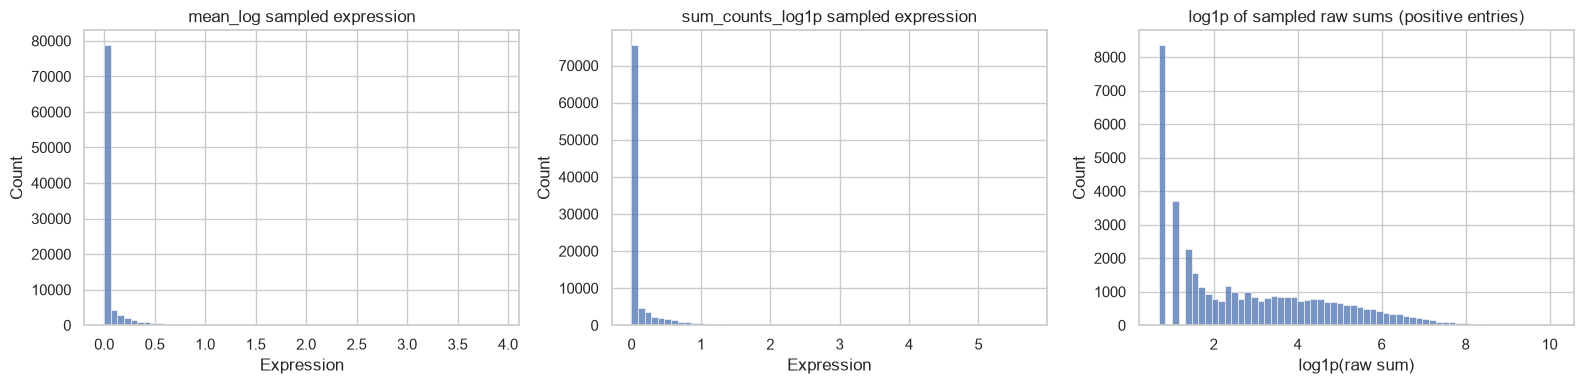

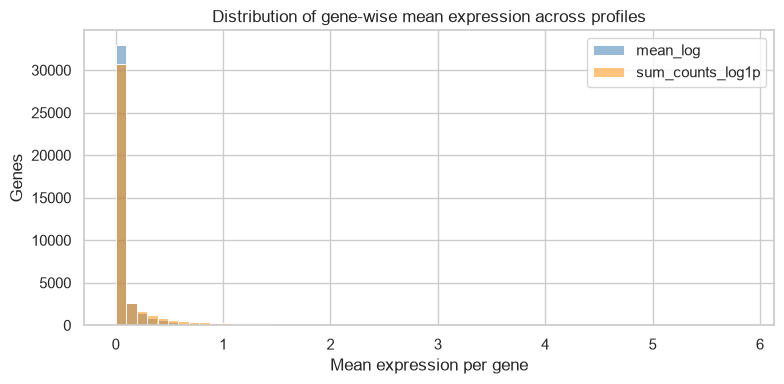

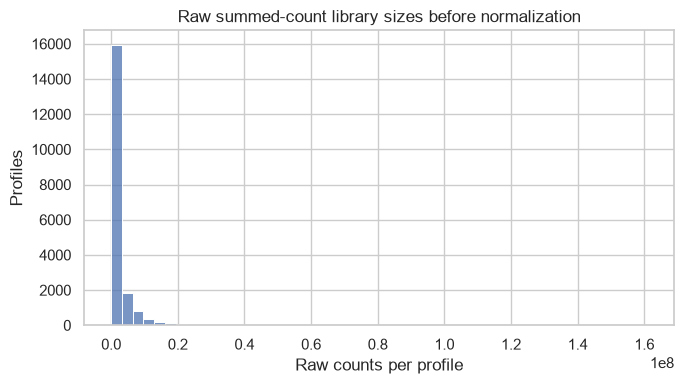

,profile_id,pearson_gene_correlation
0,pb_0000053_Donor1__B-Intermediate-Memory__IL-19,0.985047
1,pb_0000321_Donor1__CD4-Naive__IL-17C,0.983266
2,pb_0000653_Donor1__CD16-Mono__GDNF,0.988007
3,pb_0000796_Donor1__HSPC__LAP-TGF-beta1,0.983874
4,pb_0001462_Donor1__cDC__CD40L,0.993384
5,pb_0003406_Donor3__B-Naive__IL-17D,0.970498
6,pb_0005242_Donor4__CD4-Naive__Noggin,0.985901
7,pb_0005394_Donor4__CD8-Naive__IL-17A,0.982874
8,pb_0005982_Donor4__NK__TSLP,0.960970
9,pb_0007667_Donor5__NK-CD56bright__IL-18Ra,0.981083


Correlation summary (representations are not expected to match):


,pearson_gene_correlation
count,30.000000
mean,0.975187
std,0.019992
min,0.878710
25%,0.974511
50%,0.980076
75%,0.983722
max,0.993384


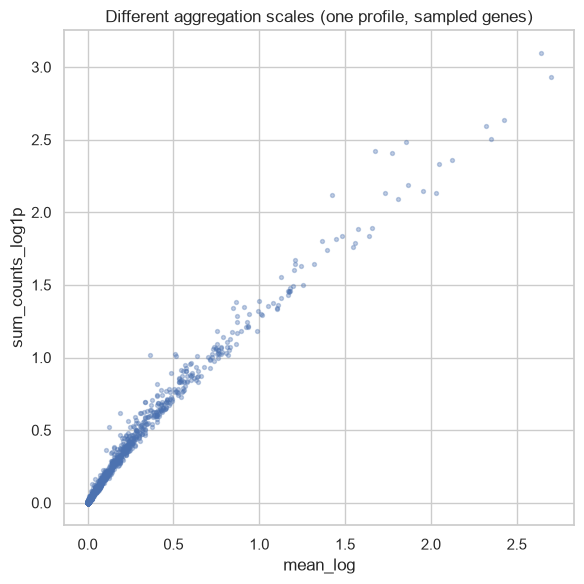

In [21]:
def matrix_finite_check(matrix):
    values = matrix.data if sparse.issparse(matrix) else np.asarray(matrix).ravel()
    return bool(np.isfinite(values).all())

def sample_expression_values(matrix, n_rows=120, n_cols=800, seed=0):
    return sparse_aware_sample(matrix, n_rows, n_cols, seed).ravel()

assert canonical.var_names.is_unique, 'Canonical gene identifiers must be unique.'
assert canonical.obs.index.is_unique, 'Canonical profile IDs must be unique.'
assert not canonical.obs.duplicated(['donor', 'cell_type', 'cytokine']).any(), 'Duplicate donor/cell_type/cytokine groups.'
assert canonical.X.shape == canonical.layers['sum_counts_raw'].shape == canonical.layers['sum_counts_log1p'].shape
assert canonical.var_names.equals(adata.var_names), 'Canonical gene order differs from source.'
assert matrix_finite_check(canonical.X), 'mean_log contains NaN or infinite values.'
assert matrix_finite_check(canonical.layers['sum_counts_raw']), 'sum_counts_raw contains NaN or infinite values.'
assert matrix_finite_check(canonical.layers['sum_counts_log1p']), 'sum_counts_log1p contains NaN or infinite values.'

raw_library_sizes = canonical.obs['raw_library_size'].to_numpy()
normalized_counts = canonical.layers['sum_counts_log1p'].copy()
normalized_counts.data = np.expm1(normalized_counts.data)
normalized_totals = np.asarray(normalized_counts.sum(axis=1)).ravel()
print('Normalized library-size totals: min/median/max',
      float(normalized_totals.min()), float(np.median(normalized_totals)), float(normalized_totals.max()))
assert np.allclose(normalized_totals, TARGET_SUM, rtol=1e-5, atol=1e-2), \
       'sum_counts_log1p profiles do not normalize back to TARGET_SUM.'

mean_values = sample_expression_values(canonical.X, seed=RANDOM_SEED)
count_log_values = sample_expression_values(canonical.layers['sum_counts_log1p'], seed=RANDOM_SEED + 1)
raw_values = sample_expression_values(canonical.layers['sum_counts_raw'], seed=RANDOM_SEED + 2)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(mean_values, bins=60, ax=axes[0]); axes[0].set(title='mean_log sampled expression', xlabel='Expression')
sns.histplot(count_log_values, bins=60, ax=axes[1]); axes[1].set(title='sum_counts_log1p sampled expression', xlabel='Expression')
sns.histplot(np.log1p(raw_values[raw_values > 0]), bins=60, ax=axes[2]); axes[2].set(title='log1p of sampled raw sums (positive entries)', xlabel='log1p(raw sum)')
plt.tight_layout(); plt.show()

mean_gene_means = np.asarray(canonical.X.mean(axis=0)).ravel()
count_log_gene_means = np.asarray(canonical.layers['sum_counts_log1p'].mean(axis=0)).ravel()
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(mean_gene_means, bins=60, color='steelblue', alpha=.55, label='mean_log', ax=ax)
sns.histplot(count_log_gene_means, bins=60, color='darkorange', alpha=.5, label='sum_counts_log1p', ax=ax)
ax.set(title='Distribution of gene-wise mean expression across profiles', xlabel='Mean expression per gene', ylabel='Genes')
ax.legend(); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(raw_library_sizes, bins=50, ax=ax)
ax.set(title='Raw summed-count library sizes before normalization', xlabel='Raw counts per profile', ylabel='Profiles')
plt.tight_layout(); plt.show()

# Compare the two different representations across a deterministic sample of profiles.
rng = np.random.default_rng(RANDOM_SEED)
profile_indices = np.sort(rng.choice(canonical.n_obs, min(30, canonical.n_obs), replace=False))
correlations = []
for i in profile_indices:
    left = canonical.X.getrow(i).toarray().ravel() if sparse.issparse(canonical.X) else np.asarray(canonical.X[i]).ravel()
    right_matrix = canonical.layers['sum_counts_log1p']
    right = right_matrix.getrow(i).toarray().ravel() if sparse.issparse(right_matrix) else np.asarray(right_matrix[i]).ravel()
    corr = np.corrcoef(left, right)[0, 1] if np.std(left) and np.std(right) else np.nan
    correlations.append({'profile_id': canonical.obs_names[i], 'pearson_gene_correlation': corr})
correlation_df = pd.DataFrame(correlations)
display(correlation_df)
print('Correlation summary (representations are not expected to match):')
display(correlation_df['pearson_gene_correlation'].describe().to_frame())

sample_profile = int(profile_indices[0])
left = canonical.X.getrow(sample_profile).toarray().ravel()
right = canonical.layers['sum_counts_log1p'].getrow(sample_profile).toarray().ravel()
gene_indices = rng.choice(canonical.n_vars, min(3000, canonical.n_vars), replace=False)
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(left[gene_indices], right[gene_indices], s=8, alpha=.35)
ax.set(title='Different aggregation scales (one profile, sampled genes)',
       xlabel='mean_log', ylabel='sum_counts_log1p')
plt.tight_layout(); plt.show()

## 5. Profile eligibility and paired-control filtering

A stimulated profile qualifies at a threshold only if both it and the same donor/cell type PBS profile meet the threshold. A PBS profile is eligible once if it supports at least one cytokine comparison; it is not duplicated when reused across cytokines.

In [22]:
def build_eligibility(canonical_obs, thresholds, control_label='PBS'):
    obs = canonical_obs[['donor', 'cell_type', 'cytokine', 'n_cells']].copy()
    obs[['donor', 'cell_type', 'cytokine']] = obs[['donor', 'cell_type', 'cytokine']].astype(str)
    count_lookup = obs.set_index(['donor', 'cell_type', 'cytokine'])['n_cells'].to_dict()
    threshold_flags = {}
    summary_rows = []

    for threshold in thresholds:
        eligible_keys = set()
        paired_by_group = {}
        for row in obs.itertuples(index=False):
            donor, cell_type, cytokine, n_cells = row
            if cytokine == str(control_label) or int(n_cells) < threshold:
                continue
            control_key = (donor, cell_type, str(control_label))
            if int(count_lookup.get(control_key, 0)) >= threshold:
                stim_key = (donor, cell_type, cytokine)
                eligible_keys.add(stim_key)
                eligible_keys.add(control_key)
                paired_by_group.setdefault((cell_type, cytokine), set()).add(donor)

        flag = []
        for row in obs.itertuples(index=False):
            key = (row.donor, row.cell_type, row.cytokine)
            flag.append(key in eligible_keys)
        threshold_flags[f'eligible_min_{threshold}'] = np.asarray(flag, dtype=bool)

        for cell_type in sorted(obs['cell_type'].unique()):
            for cytokine in sorted(obs.loc[obs['cytokine'] != str(control_label), 'cytokine'].unique()):
                donors = paired_by_group.get((cell_type, cytokine), set())
                stim_count = len(donors)
                summary_rows.append({
                    'minimum_cells': int(threshold), 'cell_type': cell_type, 'cytokine': cytokine,
                    'eligible_stimulated_profiles': stim_count,
                    'eligible_pbs_profiles': stim_count,
                    'eligible_donors': stim_count,
                    'paired_profiles': stim_count,
                })

    profile_flags = pd.DataFrame(threshold_flags, index=canonical_obs.index)
    summary = pd.DataFrame(summary_rows)
    return profile_flags, summary

eligibility_flags, eligibility_summary = build_eligibility(
    canonical.obs, ELIGIBILITY_THRESHOLDS, CONTROL_LABEL
)
for threshold in ELIGIBILITY_THRESHOLDS:
    print(f'Eligibility summary at {threshold} cells')
    display(eligibility_summary[eligibility_summary['minimum_cells'] == threshold]
            .sort_values(['cell_type', 'cytokine']).head(100))

print('Special holdout-cell coverage at primary threshold')
display(eligibility_summary[
    (eligibility_summary['minimum_cells'] == MIN_CELLS) &
    (eligibility_summary['cell_type'].isin(HOLDOUT_CELL_TYPES))
].sort_values(['cell_type', 'cytokine']))

Eligibility summary at 5 cells


,minimum_cells,cell_type,cytokine,eligible_stimulated_profiles,eligible_pbs_profiles,eligible_donors,paired_profiles
0,5,B Intermediate/Memory,4-1BBL,12,12,12,12
1,5,B Intermediate/Memory,ADSF,12,12,12,12
2,5,B Intermediate/Memory,APRIL,12,12,12,12
3,5,B Intermediate/Memory,BAFF,12,12,12,12
4,5,B Intermediate/Memory,C5a,12,12,12,12
...,...,...,...,...,...,...,...
95,5,B Naive,CD27L,12,12,12,12
96,5,B Naive,CD30L,12,12,12,12
97,5,B Naive,CD40L,12,12,12,12
98,5,B Naive,CT-1,12,12,12,12


Eligibility summary at 10 cells


,minimum_cells,cell_type,cytokine,eligible_stimulated_profiles,eligible_pbs_profiles,eligible_donors,paired_profiles
1620,10,B Intermediate/Memory,4-1BBL,12,12,12,12
1621,10,B Intermediate/Memory,ADSF,12,12,12,12
1622,10,B Intermediate/Memory,APRIL,12,12,12,12
1623,10,B Intermediate/Memory,BAFF,12,12,12,12
1624,10,B Intermediate/Memory,C5a,12,12,12,12
...,...,...,...,...,...,...,...
1715,10,B Naive,CD27L,12,12,12,12
1716,10,B Naive,CD30L,12,12,12,12
1717,10,B Naive,CD40L,12,12,12,12
1718,10,B Naive,CT-1,12,12,12,12


Eligibility summary at 20 cells


,minimum_cells,cell_type,cytokine,eligible_stimulated_profiles,eligible_pbs_profiles,eligible_donors,paired_profiles
3240,20,B Intermediate/Memory,4-1BBL,12,12,12,12
3241,20,B Intermediate/Memory,ADSF,12,12,12,12
3242,20,B Intermediate/Memory,APRIL,12,12,12,12
3243,20,B Intermediate/Memory,BAFF,12,12,12,12
3244,20,B Intermediate/Memory,C5a,12,12,12,12
...,...,...,...,...,...,...,...
3335,20,B Naive,CD27L,12,12,12,12
3336,20,B Naive,CD30L,12,12,12,12
3337,20,B Naive,CD40L,12,12,12,12
3338,20,B Naive,CT-1,12,12,12,12


Special holdout-cell coverage at primary threshold


,minimum_cells,cell_type,cytokine,eligible_stimulated_profiles,eligible_pbs_profiles,eligible_donors,paired_profiles
1800,10,CD14 Mono,4-1BBL,12,12,12,12
1801,10,CD14 Mono,ADSF,12,12,12,12
1802,10,CD14 Mono,APRIL,12,12,12,12
1803,10,CD14 Mono,BAFF,12,12,12,12
1804,10,CD14 Mono,C5a,12,12,12,12
...,...,...,...,...,...,...,...
2695,10,NK,TPO,12,12,12,12
2696,10,NK,TRAIL,12,12,12,12
2697,10,NK,TSLP,12,12,12,12
2698,10,NK,TWEAK,12,12,12,12


## 6. Training dataset construction

In [23]:
if f'eligible_min_{MIN_CELLS}' not in eligibility_flags:
    raise ValueError(f'MIN_CELLS={MIN_CELLS} must be included in ELIGIBILITY_THRESHOLDS.')

canonical_obs = canonical.obs.copy()
missing_holdouts = set(HOLDOUT_CELL_TYPES) - set(canonical_obs['cell_type'].astype(str))
if missing_holdouts:
    raise ValueError(f'Requested holdout cell types not found in canonical profiles: {sorted(missing_holdouts)}')
primary_flag = eligibility_flags[f'eligible_min_{MIN_CELLS}']
is_control = canonical_obs['cytokine'].astype(str).eq(str(CONTROL_LABEL))
is_holdout_type = canonical_obs['cell_type'].astype(str).isin(HOLDOUT_CELL_TYPES)
is_holdout_stimulated = is_holdout_type & ~is_control
training_mask = primary_flag.to_numpy() & ~is_holdout_stimulated.to_numpy()
training_indices = np.flatnonzero(training_mask)
training = canonical[training_indices].copy()

# Keep gene ordering and all expression representations exactly as canonical.
assert training.var_names.equals(canonical.var_names)
print('Canonical profiles:', canonical.n_obs)
print('Eligible profiles before holdout:', int(primary_flag.sum()))
print('Training profiles after holdout:', training.n_obs)
print('Training profiles by condition:')
display(training.obs.groupby(['cell_type', 'condition'], observed=True).size().unstack(fill_value=0))

Canonical profiles: 19459
Eligible profiles before holdout: 16689
Training profiles after holdout: 14529
Training profiles by condition:


condition,control,stimulated
cell_type,,
B Intermediate/Memory,12,1080
B Naive,12,1080
CD14 Mono,12,0
CD16 Mono,12,1004
CD4 Memory,12,1080
CD4 Naive,12,1080
CD8 Memory,12,1080
CD8 Naive,12,1079
HSPC,12,751


## 7. Holdout verification

In [24]:
training_keys = set(zip(training.obs['donor'].astype(str), training.obs['cell_type'].astype(str), training.obs['cytokine'].astype(str)))
canonical_keys = set(zip(canonical.obs['donor'].astype(str), canonical.obs['cell_type'].astype(str), canonical.obs['cytokine'].astype(str)))
heldout_summary = []
for cell_type in HOLDOUT_CELL_TYPES:
    cell_mask = canonical.obs['cell_type'].astype(str).eq(cell_type)
    ctl_mask = cell_mask & canonical.obs['cytokine'].astype(str).eq(str(CONTROL_LABEL))
    stim_mask = cell_mask & ~canonical.obs['cytokine'].astype(str).eq(str(CONTROL_LABEL))
    eligible_stim_mask = stim_mask & primary_flag
    heldout_summary.append({
        'cell_type': cell_type,
        'pbs_profiles_retained_in_training': int((training.obs['cell_type'].astype(str).eq(cell_type) & training.obs['cytokine'].astype(str).eq(str(CONTROL_LABEL))).sum()),
        'stimulated_profiles_excluded_from_training': int(stim_mask.sum()),
        'eligible_stimulated_profiles_available_for_evaluation': int(eligible_stim_mask.sum()),
        'eligible_stimulated_with_matching_pbs': int(eligible_stim_mask.sum()),
        'unique_donors_in_evaluation': int(canonical.obs.loc[eligible_stim_mask, 'donor'].nunique()),
    'cytokines_in_evaluation': int(canonical.obs.loc[eligible_stim_mask, 'cytokine'].nunique()),
    })
heldout_summary = pd.DataFrame(heldout_summary)
display(heldout_summary)

# Assertions tie the training set to canonical rather than independently aggregated profiles.
assert training.n_vars == canonical.n_vars
assert training.var_names.equals(canonical.var_names)
assert list(training.layers.keys()) == list(canonical.layers.keys())
assert not ((training.obs['cell_type'].astype(str).isin(HOLDOUT_CELL_TYPES)) &
            (training.obs['cytokine'].astype(str) != str(CONTROL_LABEL))).any(),        'Stimulated holdout profiles leaked into training.'
assert np.all(primary_flag.to_numpy()[training_indices]), 'Ineligible profile included in training.'
eligible_non_holdout = primary_flag.to_numpy() & ~is_holdout_type.to_numpy()
training_non_holdout = ~training.obs['cell_type'].astype(str).isin(HOLDOUT_CELL_TYPES).to_numpy()
assert int(eligible_non_holdout.sum()) == int(training_non_holdout.sum()), \
       'Some eligible non-holdout profiles are missing from training.'

# Every eligible control profile must be retained, and each eligible holdout stim has its PBS key.
for row in canonical.obs.loc[primary_flag].itertuples():
    key = (str(row.donor), str(row.cell_type), str(row.cytokine))
    if key[2] == str(CONTROL_LABEL):
        assert key in training_keys, f'Eligible PBS profile missing from training: {key}'
holdout_eval = canonical.obs.loc[
    canonical.obs['cell_type'].astype(str).isin(HOLDOUT_CELL_TYPES) &
    canonical.obs['cytokine'].astype(str).ne(str(CONTROL_LABEL)) & primary_flag
]
for row in holdout_eval.itertuples():
    pbs_key = (str(row.donor), str(row.cell_type), str(CONTROL_LABEL))
    assert pbs_key in training_keys, f'Missing eligible matching PBS training profile: {pbs_key}'

for row in training.obs.itertuples():
    assert int(row.n_cells) >= MIN_CELLS
    assert (str(row.donor), str(row.cell_type), str(row.cytokine)) in canonical_keys

print('Holdout and training assertions passed.')

,cell_type,pbs_profiles_retained_in_training,stimulated_profiles_excluded_from_training,eligible_stimulated_profiles_available_for_evaluation,eligible_stimulated_with_matching_pbs,unique_donors_in_evaluation,cytokines_in_evaluation
0,NK,12,1080,1080,1080,12,90
1,CD14 Mono,12,1080,1080,1080,12,90


Holdout and training assertions passed.


The canonical object retains all stimulated NK and CD14 Mono profiles. The training object excludes those stimulated profiles but retains eligible PBS profiles. Eligible holdout profiles remain available in canonical for downstream evaluation; no model training or prediction occurs here.

## 8. Save outputs and final summary

In [25]:
# Add per-threshold eligibility flags to the canonical profile metadata CSV.
profile_metadata = canonical.obs.copy()
for column in eligibility_flags.columns:
    profile_metadata[column] = eligibility_flags[column].to_numpy()
profile_metadata['eligible_primary'] = eligibility_flags[f'eligible_min_{MIN_CELLS}'].to_numpy()
profile_metadata.to_csv(PSEUDOBULK_DIR / 'pseudobulk_profile_metadata.csv', index_label='profile_id')
eligibility_summary.to_csv(PSEUDOBULK_DIR / 'pseudobulk_eligibility_thresholds.csv', index=False)

canonical_path = PSEUDOBULK_DIR / 'hcd_pseudobulk_canonical.h5ad'
training_path = PSEUDOBULK_DIR / 'hcd_pseudobulk_training.h5ad'
canonical.write_h5ad(canonical_path, compression='gzip')
training.write_h5ad(training_path, compression='gzip')

low_cell_groups = canonical.obs.loc[canonical.obs['n_cells'] < MIN_CELLS,
                                    ['donor', 'cell_type', 'cytokine', 'n_cells']]
summary = {
    'input_file_path': str(FULL_DATA_PATH),
    'input_dimensions_cells_genes': [int(adata.n_obs), int(adata.n_vars)],
    'metadata_columns': {'donor': DONOR_KEY, 'cell_type': CELL_TYPE_KEY, 'cytokine': CYTOKINE_KEY},
    'aggregation_definitions': {
        'primary': 'mean_log: mean of cell-level log-normalized expression; raw X uses normalize_total(target_sum=TARGET_SUM) then log1p per cell, matching subset_hcd.py',
        'backup': 'sum raw counts by group; normalize each profile to target sum; apply log1p',
    },
    'expression_input_mode': EXPRESSION_MODE,
    'raw_counts_source': RAW_COUNTS_SOURCE,
    'normalization_target': int(TARGET_SUM),
    'primary_cell_count_threshold': int(MIN_CELLS),
    'holdout_cell_types': list(HOLDOUT_CELL_TYPES),
    'canonical_profiles': int(canonical.n_obs),
    'training_profiles': int(training.n_obs),
    'heldout_stimulated_profiles_total': int((
        canonical.obs['cell_type'].astype(str).isin(HOLDOUT_CELL_TYPES) &
        canonical.obs['cytokine'].astype(str).ne(str(CONTROL_LABEL))
    ).sum()),
    'eligible_matched_evaluation_profiles': int(len(holdout_eval)),
    'gene_count': int(canonical.n_vars),
    'low_cell_groups_below_primary_threshold': int(len(low_cell_groups)),
    'training_profiles_not_primary_eligible': int((~primary_flag).sum()),
    'heldout_stimulated_profiles_not_eligible_for_evaluation': int(
        ((canonical.obs['cell_type'].astype(str).isin(HOLDOUT_CELL_TYPES)) &
         canonical.obs['cytokine'].astype(str).ne(str(CONTROL_LABEL)) & ~primary_flag).sum()
    ),
    'low_cell_group_examples': low_cell_groups.head(100).to_dict(orient='records'),
    'outputs': {
        'canonical_h5ad': str(canonical_path), 'training_h5ad': str(training_path),
        'profile_metadata_csv': str(PSEUDOBULK_DIR / 'pseudobulk_profile_metadata.csv'),
        'eligibility_csv': str(PSEUDOBULK_DIR / 'pseudobulk_eligibility_thresholds.csv'),
    },
}
summary_path = PSEUDOBULK_DIR / 'pseudobulk_summary.json'
summary_path.write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "input_file_path": "/Users/svneni/f26/idl/cyto-project/cytoX/data/10M_PBMC_12donor_90cytokines/10M_PBMC_cytokines.h5ad",
  "input_dimensions_cells_genes": [
    9697974,
    40352
  ],
  "metadata_columns": {
    "donor": "donor",
    "cell_type": "cell_type",
    "cytokine": "cytokine"
  },
  "aggregation_definitions": {
    "primary": "mean_log: mean of cell-level log-normalized expression; raw X uses normalize_total(target_sum=TARGET_SUM) then log1p per cell, matching subset_hcd.py",
    "backup": "sum raw counts by group; normalize each profile to target sum; apply log1p"
  },
  "expression_input_mode": "derive_log_normalized_values_from_raw_X",
  "raw_counts_source": "X (verified integer-like raw counts)",
  "normalization_target": 10000,
  "primary_cell_count_threshold": 10,
  "holdout_cell_types": [
    "NK",
    "CD14 Mono"
  ],
  "canonical_profiles": 19459,
  "training_profiles": 14529,
  "heldout_stimulated_profiles_total": 2160,
  "eligible_matched_evaluation_profiles":

In [26]:
output_paths = [
    PSEUDOBULK_DIR / 'hcd_pseudobulk_canonical.h5ad',
    PSEUDOBULK_DIR / 'hcd_pseudobulk_training.h5ad',
    PSEUDOBULK_DIR / 'pseudobulk_profile_metadata.csv',
    PSEUDOBULK_DIR / 'pseudobulk_eligibility_thresholds.csv',
    PSEUDOBULK_DIR / 'pseudobulk_summary.json',
]
output_report = []
for path in output_paths:
    if not path.is_file():
        raise FileNotFoundError(f'Expected output was not written: {path}')
    output_report.append({'path': str(path), 'size_mb': round(path.stat().st_size / (1024**2), 2)})
display(pd.DataFrame(output_report))

validation_checklist = {
    'unique_gene_ids': bool(canonical.var_names.is_unique),
    'unique_profile_ids': bool(canonical.obs_names.is_unique),
    'unique_donor_cell_type_cytokine_keys': bool(not canonical.obs.duplicated(['donor','cell_type','cytokine']).any()),
    'finite_mean_log': bool(matrix_finite_check(canonical.X)),
    'finite_raw_count_layer': bool(matrix_finite_check(canonical.layers['sum_counts_raw'])),
    'finite_sum_counts_log1p': bool(matrix_finite_check(canonical.layers['sum_counts_log1p'])),
    'training_same_gene_order': bool(training.var_names.equals(canonical.var_names)),
    'no_stimulated_holdout_in_training': bool(not ((training.obs['cell_type'].astype(str).isin(HOLDOUT_CELL_TYPES)) & training.obs['cytokine'].astype(str).ne(str(CONTROL_LABEL))).any()),
    'all_training_profiles_primary_eligible': bool(np.all(primary_flag.to_numpy()[training_indices])),
    'all_eligible_non_holdout_profiles_retained': bool(
        int(eligible_non_holdout.sum()) == int(training_non_holdout.sum())
    ),
    'eligible_holdout_profiles_have_training_pbs': all(
        (str(row.donor), str(row.cell_type), str(CONTROL_LABEL)) in training_keys
        for row in holdout_eval.itertuples()
    ),
}
display(pd.Series(validation_checklist, name='passed'))
assert all(validation_checklist.values()), 'One or more final validation checks failed.'
print(f"Done: {canonical.n_obs:,} canonical profiles; {training.n_obs:,} training profiles; {canonical.n_vars:,} genes.")
adata.file.close()

,path,size_mb
0,/Users/svneni/f26/idl/cyto-project/cytoX/data/...,3200.80
1,/Users/svneni/f26/idl/cyto-project/cytoX/data/...,2585.64
2,/Users/svneni/f26/idl/cyto-project/cytoX/data/...,1.90
3,/Users/svneni/f26/idl/cyto-project/cytoX/data/...,0.14
4,/Users/svneni/f26/idl/cyto-project/cytoX/data/...,0.01


unique_gene_ids                                True
unique_profile_ids                             True
unique_donor_cell_type_cytokine_keys           True
finite_mean_log                                True
finite_raw_count_layer                         True
finite_sum_counts_log1p                        True
training_same_gene_order                       True
no_stimulated_holdout_in_training              True
all_training_profiles_primary_eligible         True
all_eligible_non_holdout_profiles_retained     True
eligible_holdout_profiles_have_training_pbs    True
Name: passed, dtype: bool

Done: 19,459 canonical profiles; 14,529 training profiles; 40,352 genes.
